# Etapa 5: SVM contra os pontos de referência, em 10 seeds

Entrada: `data/processed/renda.csv` e `resultados/referencias.csv` (etapa 3). Grades de `src/svm.py`, escolhidas no estudo da etapa 4.

Mesmo protocolo das referências: 10 seeds, divisão estratificada 80/20, busca em grade com validação cruzada de 5 partes dentro do treino, avaliação única no teste e tempos num único núcleo.

**Modelos:**

- **SVM linear** (LinearSVC): C ∈ {0,001; 0,01; 0,1; 1; 10}.
- **SVM RBF**: C ∈ {0,1; 1; 10; 100} × gamma ∈ {0,01; 0,03; 0,1; 0,3}.
- **SVM polinomial**: grau ∈ {2, 3} × C ∈ {0,1; 1; 10}, coef0 = 1.
- **SVM RBF com pesos por classe** (`class_weight="balanced"`): os C e gamma escolhidos pela busca do RBF em cada seed, sem nova busca.

A seção 6 usa raça e sexo, que ficaram fora dos modelos, para comparar os erros entre grupos.

## 0. Configuração

In [1]:
import sys
import ast
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

from src import avaliacao, config, svm

X, y = avaliacao.carregar()
sensiveis = avaliacao.carregar_sensiveis()
referencias = pd.read_csv(config.RESULTS_DIR / "referencias.csv")
print(X.shape, "| referências:", referencias["modelo"].unique().tolist())

# aquecimento: um treino pequeno, descartado
X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, 0)
avaliacao.treinar_e_medir(svm.svm(), X_tr.iloc[:1000], y_tr.iloc[:1000], X_te, y_te);

(30139, 10) | referências: ['classe majoritária', 'regra de um corte', 'regressão logística', 'árvore de decisão', 'random forest']


## 1. As três SVMs com busca em grade

In [2]:
def svms(seed):
    cv = avaliacao.validacao_cruzada(seed)
    return {
        "SVM linear": GridSearchCV(svm.svm_linear(), svm.GRADE_LINEAR, cv=cv, n_jobs=1),
        "SVM RBF": GridSearchCV(svm.svm("rbf"), svm.GRADE_RBF, cv=cv, n_jobs=1),
        "SVM polinomial": GridSearchCV(svm.svm("poly"), svm.GRADE_POLI, cv=cv, n_jobs=1),
    }


inicio = perf_counter()
resultados = avaliacao.rodar_seeds(svms, X, y, aquecer=False)
print(f"tempo total: {(perf_counter() - inicio) / 60:.0f} min")

tempo total: 107 min


## 2. RBF com pesos por classe

In [3]:
def parametros_rbf(seed):
    texto = resultados.query("modelo == 'SVM RBF' and seed == @seed")["hiperparâmetros"].iloc[0]
    return {k.replace("modelo__", ""): v for k, v in ast.literal_eval(texto).items()}


linhas = []
for seed in config.SEEDS:
    X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed)
    modelo = svm.svm(class_weight="balanced", **parametros_rbf(seed))
    metricas, _ = avaliacao.treinar_e_medir(modelo, X_tr, y_tr, X_te, y_te)
    linhas.append({"seed": seed, "modelo": "SVM RBF com pesos", **metricas})
resultados = pd.concat([resultados, pd.DataFrame(linhas)], ignore_index=True)

resultados.to_csv(config.RESULTS_DIR / "svm.csv", index=False)
print("gravado: svm.csv", resultados.shape)

gravado: svm.csv (40, 14)


## 3. Resultados nas 10 seeds

In [4]:
todos = pd.concat([referencias, resultados], ignore_index=True)
resumo = avaliacao.resumir(todos)
resumo["vetores de suporte (média)"] = todos.groupby("modelo", sort=False)["vetores de suporte"].mean().round(0)
resumo

,acurácia,F1 macro,F1 >50K,AUC,falsos positivos (média),falsos negativos (média),tempo de treino (s) · mediana,tempo da busca (s) · mediana,tempo de previsão (ms) · mediana,vetores de suporte (média)
modelo,,,,,,,,,,
classe majoritária,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,50.0 ± 0.0,0.0,1501.0,0.0148,NaN,4.3379,NaN
regra de um corte,75.1 ± 0.0,42.9 ± 0.0,0.0 ± 0.0,75.6 ± 0.6,0.0,1501.0,0.0216,NaN,4.8009,NaN
regressão logística,84.8 ± 0.3,78.3 ± 0.4,66.5 ± 0.6,90.2 ± 0.4,324.9,591.5,0.0618,NaN,4.5432,NaN
árvore de decisão,85.2 ± 0.4,78.4 ± 0.8,66.4 ± 1.6,90.0 ± 0.4,277.4,616.7,0.0551,7.2871,5.0971,NaN
random forest,84.3 ± 0.4,78.1 ± 0.6,66.5 ± 0.8,89.1 ± 0.5,390.7,558.7,2.8409,NaN,179.9893,NaN
SVM linear,84.8 ± 0.3,78.2 ± 0.3,66.2 ± 0.5,90.2 ± 0.4,310.8,604.5,0.0493,1.1596,4.5044,NaN
SVM RBF,85.4 ± 0.4,79.0 ± 0.4,67.5 ± 0.7,88.9 ± 1.0,293.9,587.0,5.7291,477.3944,2015.7247,8764.0
SVM polinomial,85.2 ± 0.4,78.7 ± 0.4,66.9 ± 0.7,90.2 ± 0.6,298.3,596.4,3.5506,130.4408,487.6405,8128.0
SVM RBF com pesos,80.9 ± 0.3,77.6 ± 0.3,69.0 ± 0.4,89.8 ± 0.8,929.3,220.6,6.2507,NaN,2283.0701,9995.0


**Leitura da tabela** (média ± desvio de 10 seeds; tempos em mediana):

- **SVM RBF**: a melhor acurácia (85,4 ± 0,4%) e o melhor F1 macro (79,0%) de todos os modelos, com o menor total de erros sem pesos (294 falsos positivos e 587 falsos negativos). Mas a AUC (88,9 ± 1,0%) é a mais baixa entre os modelos que aprendem, fora a Random Forest, e a que mais varia entre seeds. A seção 5 explica.
- **SVM polinomial**: 85,2% de acurácia, F1 macro de 78,7% e AUC de 90,2%. Fica entre o RBF e as fronteiras retas nas métricas de corte, e empata com a melhor AUC.
- **SVM linear**: 84,8% de acurácia, F1 macro de 78,2% e AUC de 90,2%, os mesmos números da regressão logística. As duas traçam uma fronteira reta nas mesmas 80 colunas; muda só a função que cada uma minimiza no treino, e nesta base isso quase não faz diferença.
- **SVM RBF com pesos**: 80,9% de acurácia, mas o maior F1 da classe >50K (69,0%) e o menor número de falsos negativos (221, contra 587 sem pesos), em troca de 929 falsos positivos (contra 294).

Sem pesos, todos os modelos continuam errando cerca de duas vezes mais por falso negativo que por falso positivo. E os sete modelos que aprendem ficam a pouco mais de 1 ponto de acurácia um do outro (84,3% a 85,4%), longe do teto de 97,1% calculado na curadoria: a diferença entre modelos é pequena perto do que nenhum deles consegue separar com estes atributos.

## 4. Hiperparâmetros escolhidos

In [5]:
for modelo in ["SVM linear", "SVM RBF", "SVM polinomial"]:
    escolhas = resultados.loc[resultados["modelo"] == modelo, "hiperparâmetros"].str.replace("modelo__", "")
    print(modelo)
    print(escolhas.value_counts().to_string(), "\n")

SVM linear
hiperparâmetros
{'C': 0.1}     7
{'C': 1}       1
{'C': 0.01}    1
{'C': 10}      1 

SVM RBF
hiperparâmetros
{'C': 1, 'gamma': 0.3}      5
{'C': 1, 'gamma': 0.1}      4
{'C': 10, 'gamma': 0.03}    1 

SVM polinomial
hiperparâmetros
{'C': 1, 'degree': 2}    9
{'C': 1, 'degree': 3}    1 



As escolhas confirmam o mapa da etapa 4:

- **SVM linear**: C = 0,1 em 7 das 10 seeds. Como a curva de C é plana, as outras escolhas (0,01, 1 e 10) dão praticamente o mesmo resultado.
- **SVM RBF**: C = 1 em 9 seeds, com gamma = 0,3 (5 seeds) ou 0,1 (4 seeds); na seed restante, C = 10 e gamma = 0,03. As três combinações estão no platô da diagonal (gamma menor pede C maior). Gamma = 0,3 é a borda da grade, mas o mapa já mostrou que gamma = 1 piora (83,5% na validação com C = 1), então a borda não esconde um valor melhor.
- **SVM polinomial**: grau 2 e C = 1 em 9 seeds. O grau 3 não compensa: fronteira mais flexível, mesmo resultado.

A escolha entre gamma = 0,1 e 0,3 importa mais do que a validação cruzada sugere. Nas 5 seeds com gamma = 0,3, o teste dá 85,2% de acurácia e 88,0% de AUC; nas 4 com gamma = 0,1, 85,5% e 89,7%. A busca prefere 0,3 por diferenças de décimos na validação, que não se repetem no teste, e essa preferência custa quase 2 pontos de AUC e cerca de 900 vetores de suporte a mais (9.230 contra 8.340).

## 5. Comparações seed a seed

In [6]:
def comparar(metrica):
    pares = todos.pivot(index="seed", columns="modelo", values=metrica)
    comparacoes = {
        "SVM RBF − SVM linear": ("SVM RBF", "SVM linear"),
        "SVM polinomial − SVM RBF": ("SVM polinomial", "SVM RBF"),
        "SVM linear − regressão logística": ("SVM linear", "regressão logística"),
        "SVM RBF − árvore de decisão": ("SVM RBF", "árvore de decisão"),
        "SVM RBF − random forest": ("SVM RBF", "random forest"),
    }
    return pd.DataFrame({
        nome: {"diferença média (pontos)": round(100 * (pares[a] - pares[b]).mean(), 2),
               "desvio (pontos)": round(100 * (pares[a] - pares[b]).std(), 2),
               "seeds com diferença positiva": int(((pares[a] - pares[b]) > 0).sum())}
        for nome, (a, b) in comparacoes.items()
    }).T


for metrica in ["acurácia", "F1 macro", "AUC"]:
    print(metrica)
    display(comparar(metrica))

acurácia


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
SVM RBF − SVM linear,0.57,0.22,10.0
SVM polinomial − SVM RBF,-0.23,0.21,2.0
SVM linear − regressão logística,0.02,0.06,7.0
SVM RBF − árvore de decisão,0.22,0.44,6.0
SVM RBF − random forest,1.14,0.31,10.0


F1 macro


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
SVM RBF − SVM linear,0.82,0.21,10.0
SVM polinomial − SVM RBF,-0.36,0.30,1.0
SVM linear − regressão logística,-0.13,0.11,1.0
SVM RBF − árvore de decisão,0.61,0.83,8.0
SVM RBF − random forest,0.93,0.54,10.0


AUC


,diferença média (pontos),desvio (pontos),seeds com diferença positiva
SVM RBF − SVM linear,-1.31,0.74,0.0
SVM polinomial − SVM RBF,1.34,0.75,10.0
SVM linear − regressão logística,-0.02,0.05,3.0
SVM RBF − árvore de decisão,-1.09,0.78,0.0
SVM RBF − random forest,-0.25,0.72,5.0


Cada linha subtrai, seed a seed, o resultado do segundo modelo do primeiro. Com 10 seeds, uma diferença positiva em 10 de 10 é consistente; 6 de 10 é praticamente empate.

- **RBF contra SVM linear**: +0,57 ponto de acurácia e +0,82 de F1 macro, nas 10 seeds. A fronteira curva ganha de fato da reta, mas por pouco.
- **Polinomial contra RBF**: o RBF ganha em acurácia (8 de 10) e F1 macro (9 de 10), por cerca de 0,3 ponto.
- **SVM linear contra regressão logística**: diferença de 0,02 ponto de acurácia, com desvio de 0,06. São o mesmo modelo na prática.
- **RBF contra árvore de decisão**: +0,22 ponto de acurácia, com desvio de 0,44 e vitória em só 6 das 10 seeds: empate. No F1 macro o RBF ganha em 8 de 10 (+0,61).
- **RBF contra Random Forest**: +1,14 ponto de acurácia e +0,93 de F1 macro, nas 10 seeds.

**Na AUC, a ordem se inverte.** O RBF perde para a SVM linear (−1,31 ponto), para a polinomial e para a árvore nas 10 seeds, e empata com a Random Forest (5 de 10). É o ponto de atenção da etapa 4 confirmado em 10 seeds.

O motivo está no que cada métrica mede. Acurácia e F1 só olham de que lado da fronteira cada pessoa caiu. A AUC olha a ordem das notas: se quem ganha mais de 50 mil recebe nota maior que quem ganha menos. A busca escolhe pela acurácia e por isso prefere gammas altos, que ajustam bem a fronteira. Mas, com gamma alto, cada vetor de suporte só influencia a sua vizinhança: longe deles, a nota de quase todo mundo cai para o mesmo valor, e o modelo perde a capacidade de ordenar as pessoas que estão longe da fronteira, mesmo classificando-as do lado certo. A seção 4 mostra o efeito: gamma = 0,3 dá AUC de 88,0%, gamma = 0,1 dá 89,7%. Se o objetivo fosse ordenar (por exemplo, escolher as mil pessoas com mais chance de ganhar mais de 50 mil), a busca deveria escolher pela AUC, e o resultado provavelmente seria um gamma menor.

A versão com pesos, com os mesmos C e gamma, tem AUC de 89,8%, 0,9 ponto acima do RBF sem pesos: dar mais peso à classe pequena muda a função aprendida, não só o corte.

## 6. Acerto, erros e tempo

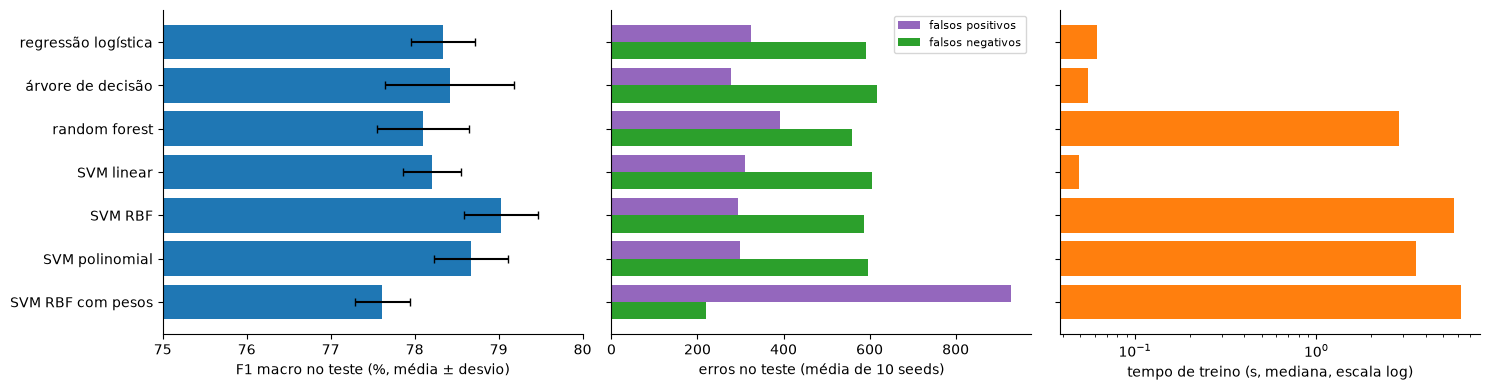

,tempo de treino (s),tempo da busca (s),tempo de previsão (ms)
modelo,,,
regressão logística,0.062,NaN,4.543
árvore de decisão,0.055,7.287,5.097
random forest,2.841,NaN,179.989
SVM linear,0.049,1.160,4.504
SVM RBF,5.729,477.394,2015.725
SVM polinomial,3.551,130.441,487.641
SVM RBF com pesos,6.251,NaN,2283.070


In [7]:
ordem = ["regressão logística", "árvore de decisão", "random forest",
         "SVM linear", "SVM RBF", "SVM polinomial", "SVM RBF com pesos"]
grupos = todos.groupby("modelo")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
media, desvio = grupos["F1 macro"].mean()[ordem], grupos["F1 macro"].std()[ordem]
eixos[0].barh(ordem, 100 * media, xerr=100 * desvio, color="tab:blue", capsize=3)
eixos[0].set_xlim(75, 80)
eixos[0].set_xlabel("F1 macro no teste (%, média ± desvio)")

erros = grupos[["falsos positivos", "falsos negativos"]].mean().loc[ordem]
eixos[1].barh(np.arange(len(ordem)) - 0.2, erros["falsos positivos"], height=0.4, color="tab:purple", label="falsos positivos")
eixos[1].barh(np.arange(len(ordem)) + 0.2, erros["falsos negativos"], height=0.4, color="tab:green", label="falsos negativos")
eixos[1].set_yticks(range(len(ordem)), [])
eixos[1].set_xlabel("erros no teste (média de 10 seeds)")
eixos[1].legend(fontsize=8)

tempo = grupos["tempo de treino (s)"].median()[ordem]
eixos[2].barh(ordem, tempo, color="tab:orange")
eixos[2].set_xscale("log")
eixos[2].set_yticks(range(len(ordem)), [])
eixos[2].set_xlabel("tempo de treino (s, mediana, escala log)")
for ax in eixos:
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

todos.groupby("modelo")[["tempo de treino (s)", "tempo da busca (s)", "tempo de previsão (ms)"]].median().loc[ordem].round(3)

**Treino** (um modelo, já com os hiperparâmetros escolhidos): a SVM linear treina em 0,05 s, tão rápida quanto a regressão logística. A polinomial leva 3,6 s e o RBF 5,7 s, o dobro da Random Forest; com pesos, 6,3 s, porque usa mais vetores de suporte (cerca de 10 mil, contra 8.800).

**Busca em grade** (por seed): 1,2 s na SVM linear (25 treinos), 2 minutos na polinomial (30 treinos) e 8 minutos no RBF (80 treinos), contra 7 s da árvore (150 treinos). As três SVMs nas 10 seeds levaram 107 minutos, quase todos na busca do RBF.

**Previsão** das 6.028 pessoas do teste: 4,5 ms na SVM linear, 0,5 s na polinomial e 2,0 s no RBF, cerca de 450 vezes a linear e 11 vezes a Random Forest, que já era a mais lenta das referências. O RBF prevê comparando cada pessoa com os cerca de 8.800 vetores de suporte; a SVM linear guarda só um peso por coluna e faz uma conta de 80 multiplicações por pessoa.

É o segundo custo da SVM com kernel, além do treino que cresce com n²: o número de vetores de suporte cresce com o treino, e a previsão cresce junto. Nesta base, 2 s para 6 mil pessoas ainda é aceitável; para prever milhões de pessoas, a SVM linear seria a escolha.

## 7. Erros por sexo e raça

Raça e sexo não entraram nos modelos. Aqui eles são usados só depois da previsão, para comparar os erros entre grupos. Para cada seed, o RBF final (com os hiperparâmetros escolhidos na seed) prevê o teste, e os erros são separados por grupo:

- **taxa de falsos negativos**: das pessoas do grupo que ganham mais de 50 mil, quantas o modelo classificou como `<=50K`;
- **taxa de falsos positivos**: das pessoas do grupo que ganham até 50 mil, quantas o modelo classificou como >50K;
- **% previsto >50K** ao lado do **% real >50K** do grupo.

Os valores são médias das 10 seeds.

In [8]:
linhas = []
for seed in config.SEEDS:
    X_tr, X_te, y_tr, y_te = avaliacao.dividir(X, y, seed)
    for nome, pesos in [("SVM RBF", None), ("SVM RBF com pesos", "balanced")]:
        previsto = svm.svm(class_weight=pesos, **parametros_rbf(seed)).fit(X_tr, y_tr).predict(X_te)
        teste = sensiveis.loc[X_te.index].assign(real=y_te.to_numpy(), previsto=previsto)
        for coluna in config.SENSIVEIS:
            for grupo, g in teste.groupby(coluna):
                linhas.append({
                    "modelo": nome, "atributo": config.NOMES[coluna], "grupo": grupo, "seed": seed,
                    "pessoas no teste": len(g),
                    "% real >50K": 100 * g["real"].mean(),
                    "% previsto >50K": 100 * g["previsto"].mean(),
                    "taxa de falsos negativos (%)": 100 * ((g["previsto"] == 0) & (g["real"] == 1)).sum() / max((g["real"] == 1).sum(), 1),
                    "taxa de falsos positivos (%)": 100 * ((g["previsto"] == 1) & (g["real"] == 0)).sum() / max((g["real"] == 0).sum(), 1),
                })
por_grupo = pd.DataFrame(linhas)
por_grupo.to_csv(config.RESULTS_DIR / "svm_erros_por_grupo.csv", index=False)
por_grupo.drop(columns="seed").groupby(["modelo", "atributo", "grupo"], sort=False).mean().round(1)

pessoas no teste  % real >50K  \
modelo            atributo grupo                                               
SVM RBF           raça     Amer-Indian-Eskimo              58.5         11.0   
                           Asian-Pac-Islander             186.3         27.3   
                           Black                          561.8         13.5   
                           Other                           45.8         10.6   
                           White                         5175.6         26.3   
                  sexo     Female                        1976.4         11.6   
                           Male                          4051.6         31.4   
SVM RBF com pesos raça     Amer-Indian-Eskimo              58.5         11.0   
                           Asian-Pac-Islander             186.3         27.3   
                           Black                          561.8         13.5   
                           Other                           45.8         10.6   
                           White                         5175.6         26.3   
                  sexo     Female                        1976.4         11.6   
                           Male                          4051.6         31.4   

                                               % previsto >50K  \
modelo            atributo grupo                                 
SVM RBF           raça     Amer-Indian-Eskimo              6.6   
                           Asian-Pac-Islander             24.1   
                           Black                           9.6   
                           Other                           8.0   
                           White                          21.3   
                  sexo     Female                          8.0   
                           Male                           25.9   
SVM RBF com pesos raça     Amer-Indian-Eskimo             20.9   
                           Asian-Pac-Islander             36.7   
                           Black                          19.9   
                           Other                          17.6   
                           White                          38.8   
                  sexo     Female                         15.1   
                           Male                           47.2   

                                               taxa de falsos negativos (%)  \
modelo            atributo grupo                                              
SVM RBF           raça     Amer-Indian-Eskimo                          54.9   
                           Asian-Pac-Islander                          35.2   
                           Black                                       45.0   
                           Other                                       50.8   
                           White                                       38.8   
                  sexo     Female                                      47.6   
                           Male                                        37.6   
SVM RBF com pesos raça     Amer-Indian-Eskimo                          27.4   
                           Asian-Pac-Islander                          16.8   
                           Black                                       18.0   
                           Other                                       18.8   
                           White                                       14.4   
                  sexo     Female                                      23.9   
                           Male                                        13.0   

                                               taxa de falsos positivos (%)  
modelo            atributo grupo                                             
SVM RBF           raça     Amer-Indian-Eskimo                           1.8  
                           Asian-Pac-Islander                           8.8  
                           Black                                        2.5  
                           Other                      

**Sexo, RBF sem pesos.** Entre as mulheres, 11,6% ganham mais de 50 mil e o modelo prevê 8,0%; entre os homens, 31,4% e 25,9%. O modelo subestima os dois grupos (é o efeito do desbalanceamento), mas erra de forma diferente em cada um:

- **falsos negativos**: das mulheres que ganham mais de 50 mil, o modelo deixa passar 47,6%; dos homens, 37,6%;
- **falsos positivos**: das mulheres que ganham até 50 mil, o modelo classifica por engano 2,2% como >50K; dos homens, 9,2%.

Para as mulheres, o modelo é mais conservador: nega mais vezes a renda alta a quem tem e quase nunca a atribui a quem não tem. O sexo não entrou no modelo, mas chega por outros atributos: o relacionamento (*Husband* é quase sempre homem e *Wife* quase sempre mulher, como a curadoria mostrou), o estado civil, a ocupação e as horas de trabalho. É o que significa dizer que remover a coluna não remove o viés: o padrão continua nos atributos que se relacionam com ela.

**Raça, RBF sem pesos.** A taxa de falsos negativos é de 38,8% entre brancos, 35,2% entre asiáticos e 45,0% entre negros. Os grupos *Amer-Indian-Eskimo* e *Other* têm taxas acima de 50%, mas cerca de 50 pessoas no teste e só 5 ou 6 com renda acima de 50 mil por seed: um erro a mais ou a menos muda a taxa em quase 20 pontos, e esses números não permitem conclusão. Só brancos (cerca de 1.360 pessoas >50K por seed) e negros (cerca de 76) têm tamanho para uma comparação.

**Com pesos.** Os falsos negativos caem em todos os grupos: de 47,6% para 23,9% entre as mulheres e de 37,6% para 13,0% entre os homens. A distância entre os sexos fica parecida em pontos (10 para 11), e os falsos positivos sobem muito mais para os homens (9,2% para 29,0%) que para as mulheres (2,2% para 7,1%). Os pesos deslocam o corte igualmente para todos e não corrigem a diferença entre grupos; isso exigiria técnicas próprias (por exemplo, cortes diferentes por grupo), fora do escopo deste trabalho.

**Resultado.** Em 10 seeds, pelo mesmo protocolo das referências:

- **SVM RBF**: a melhor acurácia (85,4%) e o melhor F1 macro (79,0%). Supera a SVM linear e a Random Forest nas 10 seeds, mas empata com a árvore ajustada em acurácia (vence em 6 de 10).
- **SVM polinomial** (grau 2): 85,2%, logo abaixo do RBF, com AUC melhor.
- **SVM linear**: 84,8%, igual à regressão logística em todas as métricas. Treina em 0,05 s.
- **AUC**: o RBF tem a pior AUC entre as SVMs (88,9%, contra 90,2% da linear e da polinomial) e perde para a SVM linear nas 10 seeds. A busca escolhe pela acurácia e prefere gammas altos, que acertam o lado da fronteira mas ordenam pior as pessoas longe dela.
- **Pesos por classe**: os falsos negativos caem de 587 para 221 (o modelo encontra 85% das pessoas de renda alta, contra 61%), e os falsos positivos sobem de 294 para 929.
- **Custo**: a busca do RBF leva 8 minutos por seed, e a previsão, 2 s para 6 mil pessoas, 450 vezes a SVM linear.
- **Erros por grupo**: o RBF deixa passar 47,6% das mulheres de renda alta, contra 37,6% dos homens, sem que o sexo esteja no modelo. Os pesos reduzem os falsos negativos de todos, mas não a diferença entre os grupos.

O desafio da etapa 3 era superar 85% de acurácia e 78% de F1 macro e reduzir os falsos negativos sem trocar por falsos positivos demais. O RBF supera os dois números, mas por margens pequenas, e sem pesos reduz pouco os falsos negativos (587, contra 592 da regressão logística). Com pesos, reduz muito, ao preço de três vezes mais falsos positivos. Nesta base, a fronteira curva da SVM ganha menos de 1 ponto da reta, e a SVM linear entrega quase o mesmo resultado a uma fração do custo.